# ☕ ANALISIS DATA NUSA BREW COFFEE SHOP
---
**Periode:** 1 Juli 2026 – 30 September 2026 (92 Hari)

Notebook ini menganalisis data transaksi NUSA BREW Coffee Shop secara komprehensif, meliputi:
1. Eksplorasi & Pembersihan Data
2. Analisis Penjualan (Revenue)
3. Analisis Produk & Kategori
4. Analisis Pelanggan
5. Analisis Tren Waktu (Time Series)
6. Analisis Promosi & Diskon
7. Analisis Tipe Order & Metode Pembayaran
8. Analisis Profitabilitas
9. Kesimpulan & Rekomendasi

## 1. Setup & Import Library

In [2]:
# Install dependencies jika belum ada
# !pip install pandas matplotlib seaborn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Format angka Rupiah
def format_rupiah(x, pos=None):
    """Format angka ke format Rupiah."""
    if abs(x) >= 1_000_000:
        return f'Rp {x/1_000_000:,.1f} Jt'
    elif abs(x) >= 1_000:
        return f'Rp {x/1_000:,.0f} Rb'
    else:
        return f'Rp {x:,.0f}'

def format_number(x):
    """Format angka dengan separator ribuan."""
    return f'{x:,.0f}'

print('Library berhasil di-import!')

Library berhasil di-import!


## 2. Load Data

In [3]:
# Load semua sheet dari file Excel
file_path = 'NUSA BREW_Dataset.xlsx'

# Sheet 1: Data transaksi utama
df = pd.read_excel(file_path, sheet_name='DATA_CLEAN')

# Sheet 2: Tren harian (skiprows=3 karena ada 3 baris header/deskripsi)
df_daily = pd.read_excel(file_path, sheet_name='DAILY_TREND', skiprows=3)

# Sheet 3: Biaya operasional (skiprows=4 karena ada 4 baris header/deskripsi + baris kosong)
df_opex = pd.read_excel(file_path, sheet_name='OPERATING_COSTS', skiprows=4)

# Sheet 4: Katalog produk (skiprows=4)
df_catalog = pd.read_excel(file_path, sheet_name='PRODUCT_CATALOG', skiprows=4)

print(f'DATA_CLEAN     : {df.shape[0]:,} baris x {df.shape[1]} kolom')
print(f'DAILY_TREND    : {df_daily.shape[0]:,} baris x {df_daily.shape[1]} kolom')
print(f'OPERATING_COSTS: {df_opex.shape[0]:,} baris x {df_opex.shape[1]} kolom')
print(f'PRODUCT_CATALOG: {df_catalog.shape[0]:,} baris x {df_catalog.shape[1]} kolom')

DATA_CLEAN     : 7,000 baris x 21 kolom
DAILY_TREND    : 92 baris x 5 kolom
OPERATING_COSTS: 3 baris x 8 kolom
PRODUCT_CATALOG: 16 baris x 5 kolom


## 3. Eksplorasi & Pembersihan Data

In [4]:
# Lihat struktur data utama
print('='*60)
print('STRUKTUR DATA TRANSAKSI (DATA_CLEAN)')
print('='*60)
df.info()

STRUKTUR DATA TRANSAKSI (DATA_CLEAN)
<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Transaction_ID   7000 non-null   str           
 1   Date             7000 non-null   datetime64[us]
 2   Day              7000 non-null   str           
 3   Time             7000 non-null   str           
 4   Time_Slot        7000 non-null   str           
 5   Customer_ID      7000 non-null   str           
 6   Customer_Type    7000 non-null   str           
 7   Product          7000 non-null   str           
 8   Category         7000 non-null   str           
 9   Quantity         7000 non-null   int64         
 10  Unit_Price       7000 non-null   int64         
 11  Promotion        7000 non-null   str           
 12  Discount_Rate    7000 non-null   float64       
 13  Gross_Sales      7000 non-null   int64         
 14  Discount_Amoun

In [5]:
# Preview 5 baris pertama
df.head()

,Transaction_ID,Date,Day,Time,Time_Slot,Customer_ID,Customer_Type,Product,Category,Quantity,...,Promotion,Discount_Rate,Gross_Sales,Discount_Amount,Net_Sales,Channel,Payment,Unit_COGS,COGS_Total,Gross_Profit
0,TRX00001,2026-07-01,Rabu,07:02,Pagi,GEN0048,Umum,Breakfast Combo,Bundle,1,...,DISKON20,0.2,45000,9000,36000,Dine-in,QRIS,21000,21000,15000
1,TRX00002,2026-07-01,Rabu,08:27,Pagi,STU0569,Mahasiswa,Beef Rice Bowl,Food,1,...,Tanpa Promo,0.0,39000,0,39000,Delivery,QRIS,22000,22000,17000
2,TRX00003,2026-07-01,Rabu,08:29,Pagi,STU0042,Mahasiswa,Matcha Latte,Non-Coffee,1,...,Tanpa Promo,0.0,32000,0,32000,Dine-in,QRIS,14000,14000,18000
3,TRX00004,2026-07-01,Rabu,08:35,Pagi,EMP0006,Karyawan,Café Latte,Coffee,1,...,Tanpa Promo,0.0,30000,0,30000,Takeaway,Debit,12500,12500,17500
4,TRX00005,2026-07-01,Rabu,08:37,Pagi,EMP0187,Karyawan,Breakfast Combo,Bundle,1,...,DISKON20,0.2,45000,9000,36000,Takeaway,Debit,21000,21000,15000


In [6]:
# Cek missing values
print('='*60)
print('CEK MISSING VALUES')
print('='*60)
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
if missing.sum() > 0:
    print(missing_df[missing_df['Missing Count'] > 0])
else:
    print('Tidak ada missing values!')
print(f'\nTotal missing values: {missing.sum()}')

CEK MISSING VALUES
Tidak ada missing values!

Total missing values: 0


In [7]:
# Cek duplikat berdasarkan Transaction ID
duplicates = df['Transaction_ID'].duplicated().sum()
print(f'Duplikat Transaction ID: {duplicates}')
print(f'Unique Transaction ID  : {df["Transaction_ID"].nunique():,}')
print(f'Total baris            : {len(df):,}')

Duplikat Transaction ID: 0
Unique Transaction ID  : 7,000
Total baris            : 7,000


In [8]:
# Lihat nama kolom asli
print('Nama kolom asli:')
for i, col in enumerate(df.columns):
    print(f'  [{i}] {col} (dtype: {df[col].dtype})')

Nama kolom asli:
  [0] Transaction_ID (dtype: str)
  [1] Date (dtype: datetime64[us])
  [2] Day (dtype: str)
  [3] Time (dtype: str)
  [4] Time_Slot (dtype: str)
  [5] Customer_ID (dtype: str)
  [6] Customer_Type (dtype: str)
  [7] Product (dtype: str)
  [8] Category (dtype: str)
  [9] Quantity (dtype: int64)
  [10] Unit_Price (dtype: int64)
  [11] Promotion (dtype: str)
  [12] Discount_Rate (dtype: float64)
  [13] Gross_Sales (dtype: int64)
  [14] Discount_Amount (dtype: int64)
  [15] Net_Sales (dtype: int64)
  [16] Channel (dtype: str)
  [17] Payment (dtype: str)
  [18] Unit_COGS (dtype: int64)
  [19] COGS_Total (dtype: int64)
  [20] Gross_Profit (dtype: int64)


In [9]:
# Rename kolom agar konsisten dan mudah diakses
# Kolom asli: Transaction_ID, Date, Day, Time, Time_Slot, Customer_ID, Customer_Type,
#             Product, Category, Quantity, Unit_Price, Promotion, Discount_Rate,
#             Gross_Sales, Discount_Amount, Net_Sales, Channel, Payment, Unit_COGS,
#             COGS_Total, Gross_Profit

df = df.rename(columns={
    'Time_Slot': 'Session',
    'Quantity': 'Qty',
    'Promotion': 'Promo',
    'Discount_Rate': 'Discount_Pct',
    'Discount_Amount': 'Discount_Amt',
    'Channel': 'Order_Type',
    'COGS_Total': 'Total_COGS'
})

# Konversi tipe data
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M')
df['Month_Name'] = df['Date'].dt.strftime('%B %Y')
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['Day_of_Week'] = df['Date'].dt.day_name()

# Konversi Discount_Pct dari desimal (0.2) ke persen (20)
df['Discount_Pct_Display'] = (df['Discount_Pct'] * 100).round(0).astype(int)

# Pastikan kolom numerik bertipe numerik
numeric_cols = ['Qty', 'Unit_Price', 'Gross_Sales', 'Discount_Amt', 'Net_Sales', 'Unit_COGS', 'Total_COGS', 'Gross_Profit']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Kolom berhasil di-rename dan tipe data dikonversi!')
print(f'\nPeriode data: {df["Date"].min().strftime("%d %B %Y")} - {df["Date"].max().strftime("%d %B %Y")}')
print(f'Jumlah hari : {df["Date"].nunique()} hari')
print(f'\nNama kolom setelah rename:')
print(list(df.columns))

Kolom berhasil di-rename dan tipe data dikonversi!

Periode data: 01 July 2026 - 30 September 2026
Jumlah hari : 92 hari

Nama kolom setelah rename:
['Transaction_ID', 'Date', 'Day', 'Time', 'Session', 'Customer_ID', 'Customer_Type', 'Product', 'Category', 'Qty', 'Unit_Price', 'Promo', 'Discount_Pct', 'Gross_Sales', 'Discount_Amt', 'Net_Sales', 'Order_Type', 'Payment', 'Unit_COGS', 'Total_COGS', 'Gross_Profit', 'Month', 'Month_Name', 'Week', 'Day_of_Week', 'Discount_Pct_Display']


In [10]:
# Cek nilai unik untuk kolom kategorikal
print('='*60)
print('NILAI UNIK KOLOM KATEGORIKAL')
print('='*60)
cat_cols_check = ['Session', 'Customer_Type', 'Category', 'Promo', 'Order_Type', 'Payment']
for col in cat_cols_check:
    print(f'\n{col}: {df[col].unique().tolist()}')

NILAI UNIK KOLOM KATEGORIKAL

Session: ['Pagi', 'Siang', 'Sore', 'Malam']

Customer_Type: ['Umum', 'Mahasiswa', 'Karyawan']

Category: ['Bundle', 'Food', 'Non-Coffee', 'Coffee', 'Snack']

Promo: ['DISKON20', 'Tanpa Promo', 'MORNING10', 'BUNDLE15']

Order_Type: ['Dine-in', 'Delivery', 'Takeaway']

Payment: ['QRIS', 'Debit', 'Cash']


In [11]:
# Statistik deskriptif untuk kolom numerik
print('='*60)
print('STATISTIK DESKRIPTIF')
print('='*60)
df[numeric_cols].describe().round(0)

STATISTIK DESKRIPTIF


,Qty,Unit_Price,Gross_Sales,Discount_Amt,Net_Sales,Unit_COGS,Total_COGS,Gross_Profit
count,7000.0,7000.0,7000.0,7000.0,7000.0,7000.0,7000.0,7000.0
mean,1.0,28598.0,35818.0,812.0,35006.0,13542.0,16962.0,18044.0
std,1.0,6908.0,17566.0,2531.0,17370.0,4472.0,9342.0,9540.0
min,1.0,18000.0,18000.0,0.0,14400.0,6500.0,6500.0,4200.0
25%,1.0,24000.0,24000.0,0.0,24000.0,10000.0,12500.0,11600.0
50%,1.0,25000.0,30000.0,0.0,30000.0,14000.0,15000.0,16000.0
75%,1.0,32000.0,43000.0,0.0,43000.0,15000.0,20000.0,18000.0
max,3.0,45000.0,135000.0,27000.0,135000.0,22000.0,66000.0,72000.0


---
## 4. Analisis Penjualan (Revenue Analysis)

In [12]:
# ===== RINGKASAN PENJUALAN KESELURUHAN =====
total_transactions = df['Transaction_ID'].nunique()
total_items_sold = df['Qty'].sum()
total_gross_sales = df['Gross_Sales'].sum()
total_discount = df['Discount_Amt'].sum()
total_net_sales = df['Net_Sales'].sum()
total_cogs = df['Total_COGS'].sum()
total_gross_profit = df['Gross_Profit'].sum()
avg_ticket = total_net_sales / total_transactions
avg_items_per_trx = total_items_sold / total_transactions
gross_margin = (total_gross_profit / total_net_sales * 100)

print('='*60)
print('RINGKASAN PENJUALAN KESELURUHAN (92 Hari)')
print('='*60)
print(f'  Total Transaksi       : {total_transactions:>10,}')
print(f'  Total Item Terjual    : {total_items_sold:>10,.0f}')
print(f'  Gross Sales           : Rp {total_gross_sales:>12,.0f}')
print(f'  Total Diskon          : Rp {total_discount:>12,.0f}')
print(f'  Net Sales             : Rp {total_net_sales:>12,.0f}')
print(f'  Total COGS            : Rp {total_cogs:>12,.0f}')
print(f'  Gross Profit          : Rp {total_gross_profit:>12,.0f}')
print(f'  Gross Margin          : {gross_margin:>10.1f}%')
print(f'  Avg Ticket Size       : Rp {avg_ticket:>12,.0f}')
print(f'  Avg Items/Transaksi   : {avg_items_per_trx:>10.2f}')

RINGKASAN PENJUALAN KESELURUHAN (92 Hari)
  Total Transaksi       :      7,000
  Total Item Terjual    :      8,774
  Gross Sales           : Rp  250,725,000
  Total Diskon          : Rp    5,686,300
  Net Sales             : Rp  245,038,700
  Total COGS            : Rp  118,733,000
  Gross Profit          : Rp  126,305,700
  Gross Margin          :       51.5%
  Avg Ticket Size       : Rp       35,006
  Avg Items/Transaksi   :       1.25


In [13]:
# ===== PENJUALAN PER BULAN =====
monthly_sales = df.groupby('Month').agg(
    Transaksi=('Transaction_ID', 'nunique'),
    Items_Sold=('Qty', 'sum'),
    Gross_Sales=('Gross_Sales', 'sum'),
    Discount=('Discount_Amt', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    COGS=('Total_COGS', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index()

monthly_sales['Avg_Ticket'] = monthly_sales['Net_Sales'] / monthly_sales['Transaksi']
monthly_sales['Margin_%'] = (monthly_sales['Gross_Profit'] / monthly_sales['Net_Sales'] * 100).round(1)

print('PENJUALAN PER BULAN')
print('='*80)
monthly_sales

PENJUALAN PER BULAN


,Month,Transaksi,Items_Sold,Gross_Sales,Discount,Net_Sales,COGS,Gross_Profit,Avg_Ticket,Margin_%
0,2026-07,2450,3092,88017000,1388300,86628700,41748500,44880200,35358.653061,51.8
1,2026-08,1960,2444,70165000,2902800,67262200,33322000,33940200,34317.448980,50.5
2,2026-09,2590,3238,92543000,1395200,91147800,43662500,47485300,35192.200772,52.1


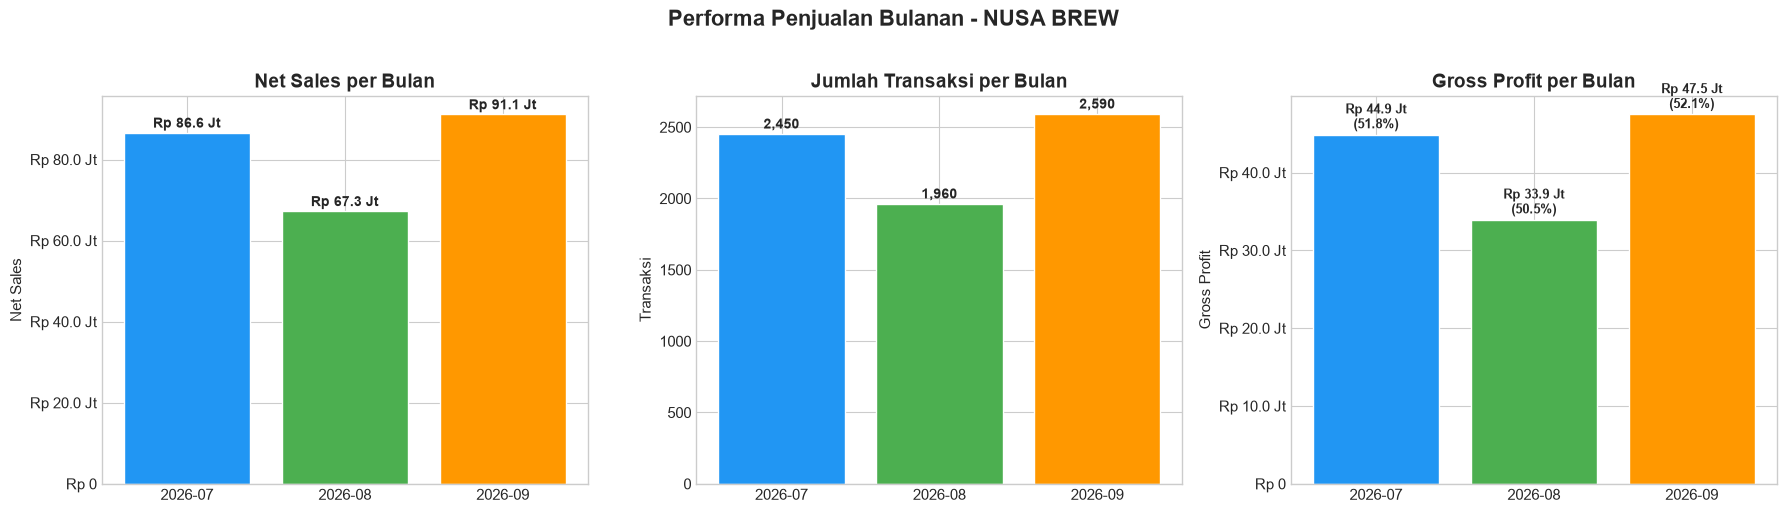

In [14]:
# Visualisasi: Net Sales & Gross Profit per Bulan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

months = monthly_sales['Month'].astype(str).tolist()

# Chart 1: Net Sales per Bulan
bars1 = axes[0].bar(months, monthly_sales['Net_Sales'], color=['#2196F3', '#4CAF50', '#FF9800'], edgecolor='white')
axes[0].set_title('Net Sales per Bulan')
axes[0].set_ylabel('Net Sales')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for bar, val in zip(bars1, monthly_sales['Net_Sales']):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 500000,
                 f'Rp {val/1_000_000:.1f} Jt', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Chart 2: Transaksi per Bulan
bars2 = axes[1].bar(months, monthly_sales['Transaksi'], color=['#2196F3', '#4CAF50', '#FF9800'], edgecolor='white')
axes[1].set_title('Jumlah Transaksi per Bulan')
axes[1].set_ylabel('Transaksi')
for bar, val in zip(bars2, monthly_sales['Transaksi']):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 20,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Chart 3: Gross Profit & Margin
bars3 = axes[2].bar(months, monthly_sales['Gross_Profit'], color=['#2196F3', '#4CAF50', '#FF9800'], edgecolor='white')
axes[2].set_title('Gross Profit per Bulan')
axes[2].set_ylabel('Gross Profit')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for bar, val, margin in zip(bars3, monthly_sales['Gross_Profit'], monthly_sales['Margin_%']):
    axes[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 300000,
                 f'Rp {val/1_000_000:.1f} Jt\n({margin}%)', ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.suptitle('Performa Penjualan Bulanan - NUSA BREW', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 5. Analisis Produk & Kategori

In [15]:
# ===== PENJUALAN PER KATEGORI =====
cat_sales = df.groupby('Category').agg(
    Transaksi=('Transaction_ID', 'count'),
    Qty=('Qty', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index()

cat_sales['Avg_Price'] = (cat_sales['Net_Sales'] / cat_sales['Qty']).round(0)
cat_sales['Margin_%'] = (cat_sales['Gross_Profit'] / cat_sales['Net_Sales'] * 100).round(1)
cat_sales['Revenue_Share_%'] = (cat_sales['Net_Sales'] / cat_sales['Net_Sales'].sum() * 100).round(1)
cat_sales = cat_sales.sort_values('Net_Sales', ascending=False)

print('PENJUALAN PER KATEGORI')
print('='*80)
cat_sales

PENJUALAN PER KATEGORI


,Category,Transaksi,Qty,Net_Sales,Gross_Profit,Avg_Price,Margin_%,Revenue_Share_%
1,Coffee,2685,3367,84617500,39733000,25131.0,47.0,34.5
3,Non-Coffee,1430,1773,47922800,28155800,27029.0,58.8,19.6
2,Food,883,1107,39532800,17242800,35712.0,43.6,16.1
4,Snack,1328,1677,36823400,22270900,21958.0,60.5,15.0
0,Bundle,674,850,36142200,18903200,42520.0,52.3,14.7


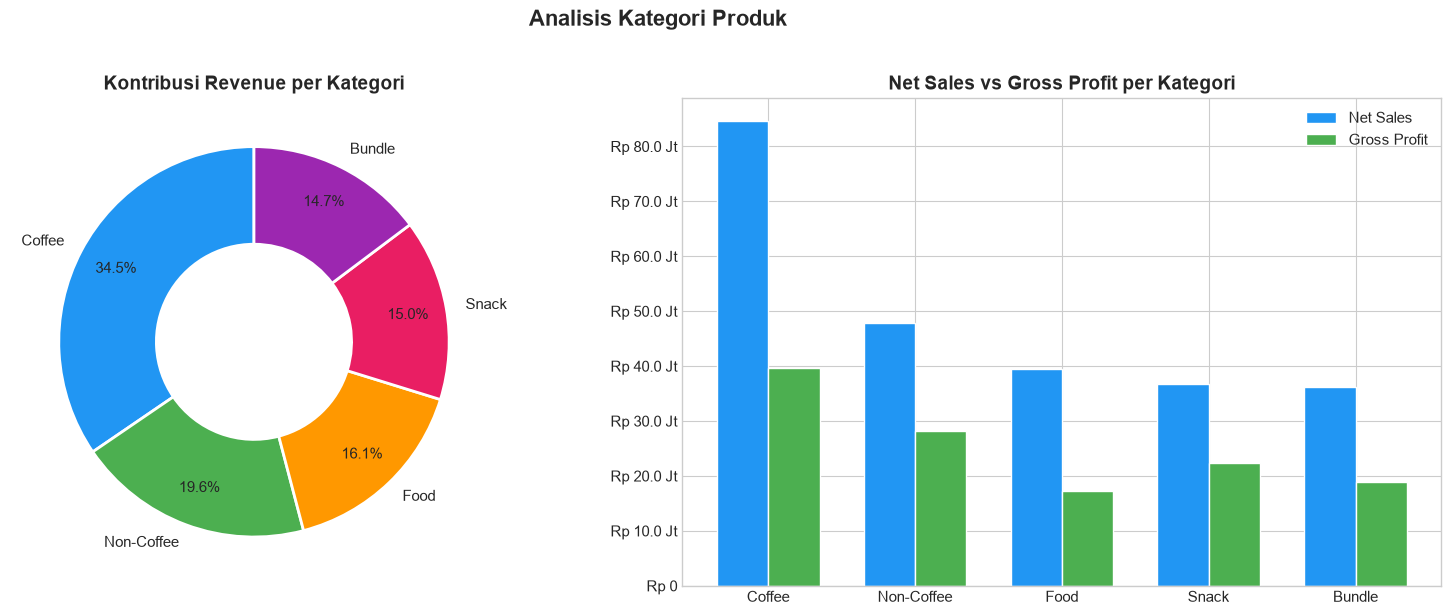

In [16]:
# Visualisasi: Kategori - Donut Chart & Bar
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0']

# Donut Chart: Revenue Share
wedges, texts, autotexts = axes[0].pie(
    cat_sales['Net_Sales'], labels=cat_sales['Category'],
    autopct='%1.1f%%', startangle=90, colors=colors,
    textprops={'fontsize': 11}, pctdistance=0.8,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2)
)
axes[0].set_title('Kontribusi Revenue per Kategori', fontweight='bold')

# Bar Chart: Net Sales & Gross Profit per Kategori
x = np.arange(len(cat_sales))
width = 0.35
axes[1].bar(x - width/2, cat_sales['Net_Sales'].values, width, label='Net Sales', color='#2196F3', edgecolor='white')
axes[1].bar(x + width/2, cat_sales['Gross_Profit'].values, width, label='Gross Profit', color='#4CAF50', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(cat_sales['Category'].values)
axes[1].set_title('Net Sales vs Gross Profit per Kategori', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
axes[1].legend()

plt.suptitle('Analisis Kategori Produk', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# ===== TOP PRODUK BERDASARKAN BERBAGAI METRIK =====
product_sales = df.groupby(['Product', 'Category']).agg(
    Qty=('Qty', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum'),
    Transaksi=('Transaction_ID', 'count')
).reset_index()

product_sales['Margin_%'] = (product_sales['Gross_Profit'] / product_sales['Net_Sales'] * 100).round(1)
product_sales['Revenue_Share_%'] = (product_sales['Net_Sales'] / product_sales['Net_Sales'].sum() * 100).round(1)

print('RANKING PRODUK BERDASARKAN NET SALES')
print('='*80)
product_sales.sort_values('Net_Sales', ascending=False)

RANKING PRODUK BERDASARKAN NET SALES


,Product,Category,Qty,Net_Sales,Gross_Profit,Transaksi,Margin_%,Revenue_Share_%
12,Iced Aren Coffee,Coffee,1913,44832000,16137000,1520,36.0,18.3
15,Study Combo,Bundle,611,25580700,13360700,492,52.2,10.4
6,Chicken Rice Bowl,Food,688,23593500,10521500,551,44.6,9.6
14,Matcha Latte,Non-Coffee,691,21606400,11932400,555,55.2,8.8
4,Café Latte,Coffee,661,19344000,11081500,531,57.3,7.9
1,Beef Rice Bowl,Food,419,15939300,6721300,332,42.2,6.5
11,French Fries,Snack,614,14421600,8281600,497,57.4,5.9
13,Lemon Tea,Non-Coffee,624,13365000,8997000,496,67.3,5.5
7,Chocolate,Non-Coffee,458,12951400,7226400,379,55.8,5.3
3,Brownie,Snack,587,12643400,8240900,461,65.2,5.2


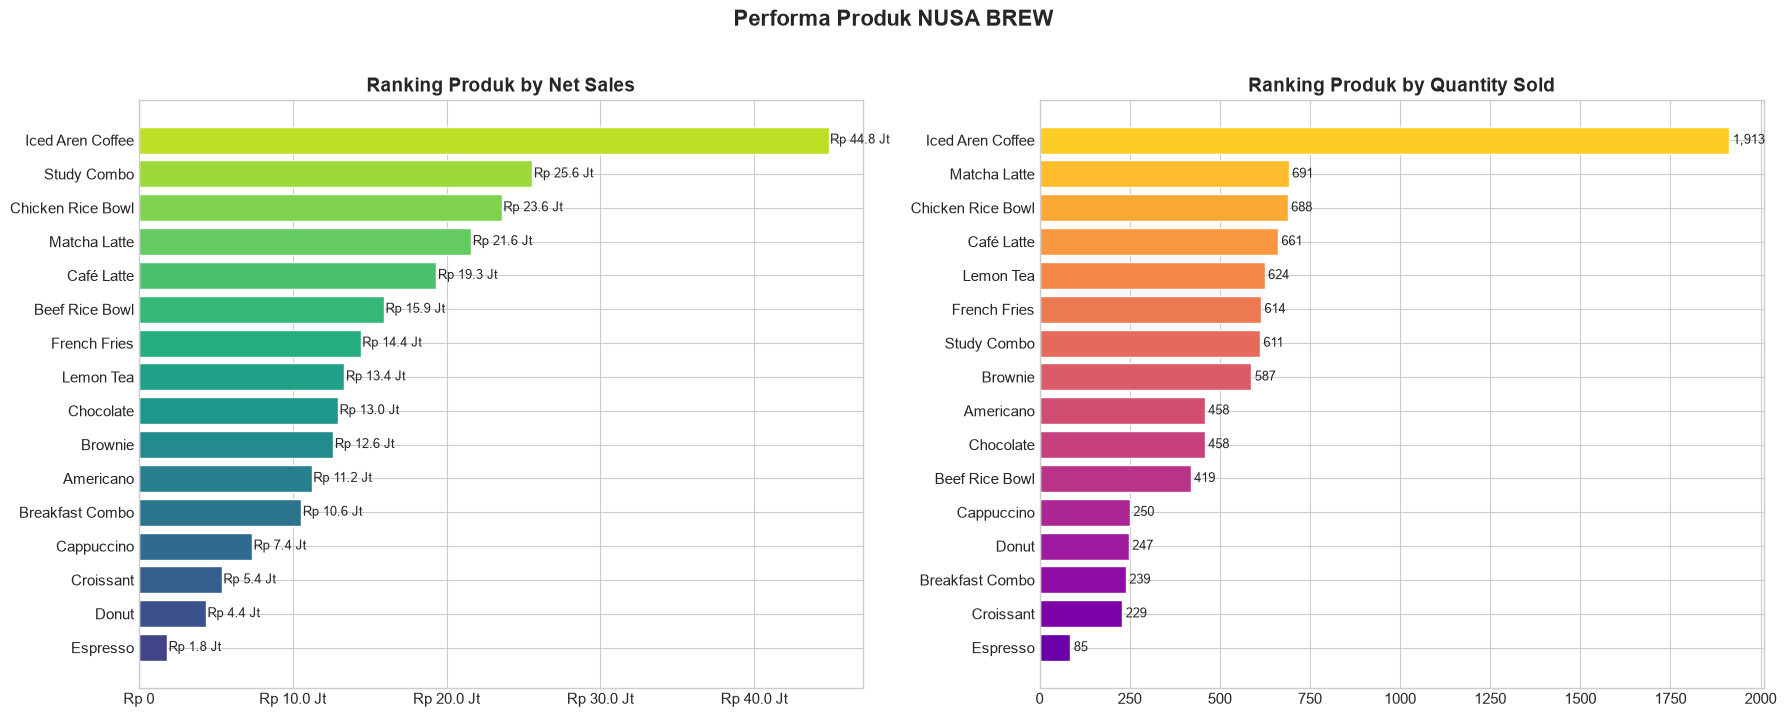

In [18]:
# Visualisasi: Top Produk
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Top produk by Revenue
top_rev = product_sales.sort_values('Net_Sales', ascending=True)
colors_rev = plt.cm.viridis(np.linspace(0.2, 0.9, len(top_rev)))
axes[0].barh(top_rev['Product'], top_rev['Net_Sales'], color=colors_rev, edgecolor='white')
axes[0].set_title('Ranking Produk by Net Sales', fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for i, (val, product) in enumerate(zip(top_rev['Net_Sales'], top_rev['Product'])):
    axes[0].text(val + 100000, i, f'Rp {val/1_000_000:.1f} Jt', va='center', fontsize=9)

# Top produk by Qty
top_qty = product_sales.sort_values('Qty', ascending=True)
colors_qty = plt.cm.plasma(np.linspace(0.2, 0.9, len(top_qty)))
axes[1].barh(top_qty['Product'], top_qty['Qty'], color=colors_qty, edgecolor='white')
axes[1].set_title('Ranking Produk by Quantity Sold', fontweight='bold')
for i, (val, product) in enumerate(zip(top_qty['Qty'], top_qty['Product'])):
    axes[1].text(val + 10, i, f'{val:,.0f}', va='center', fontsize=9)

plt.suptitle('Performa Produk NUSA BREW', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

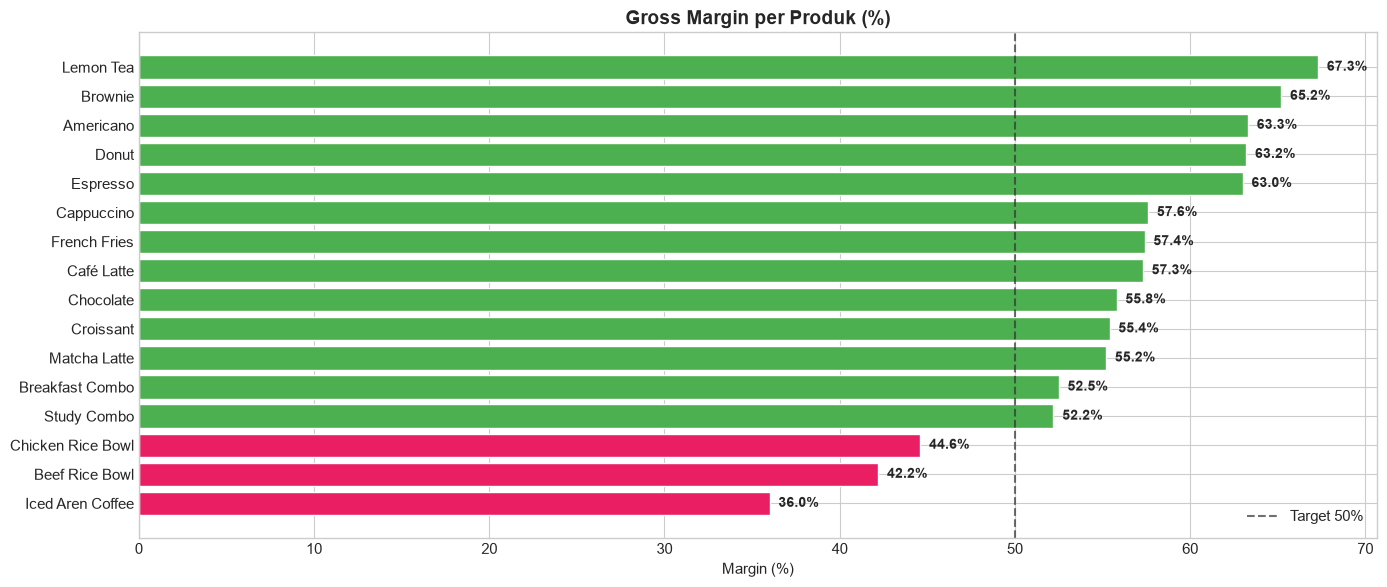

In [19]:
# ===== MARGIN ANALYSIS PER PRODUK =====
fig, ax = plt.subplots(figsize=(14, 6))

margin_sorted = product_sales.sort_values('Margin_%', ascending=True)
colors_margin = ['#E91E63' if m < 50 else '#4CAF50' for m in margin_sorted['Margin_%']]

bars = ax.barh(margin_sorted['Product'], margin_sorted['Margin_%'], color=colors_margin, edgecolor='white')
ax.axvline(x=50, color='#333', linestyle='--', alpha=0.7, label='Target 50%')
ax.set_title('Gross Margin per Produk (%)', fontweight='bold', fontsize=14)
ax.set_xlabel('Margin (%)')

for bar, val in zip(bars, margin_sorted['Margin_%']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2.,
            f'{val:.1f}%', ha='left', va='center', fontweight='bold', fontsize=10)

ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Analisis Pelanggan

In [20]:
# ===== ANALISIS PER TIPE PELANGGAN =====
cust_type = df.groupby('Customer_Type').agg(
    Unique_Customers=('Customer_ID', 'nunique'),
    Total_Transaksi=('Transaction_ID', 'count'),
    Total_Qty=('Qty', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum'),
    Avg_Qty=('Qty', 'mean')
).reset_index()

cust_type['Avg_Spend'] = (cust_type['Net_Sales'] / cust_type['Total_Transaksi']).round(0)
cust_type['Revenue_Share_%'] = (cust_type['Net_Sales'] / cust_type['Net_Sales'].sum() * 100).round(1)
cust_type['Trx_per_Customer'] = (cust_type['Total_Transaksi'] / cust_type['Unique_Customers']).round(1)

print('ANALISIS PER TIPE PELANGGAN')
print('='*80)
cust_type

ANALISIS PER TIPE PELANGGAN


,Customer_Type,Unique_Customers,Total_Transaksi,Total_Qty,Net_Sales,Gross_Profit,Avg_Qty,Avg_Spend,Revenue_Share_%,Trx_per_Customer
0,Karyawan,282,1336,1658,47246450,24830450,1.241018,35364.0,19.3,4.7
1,Mahasiswa,699,3381,4164,114107800,57915300,1.231588,33750.0,46.6,4.8
2,Umum,638,2283,2952,83684450,43559950,1.293035,36655.0,34.2,3.6


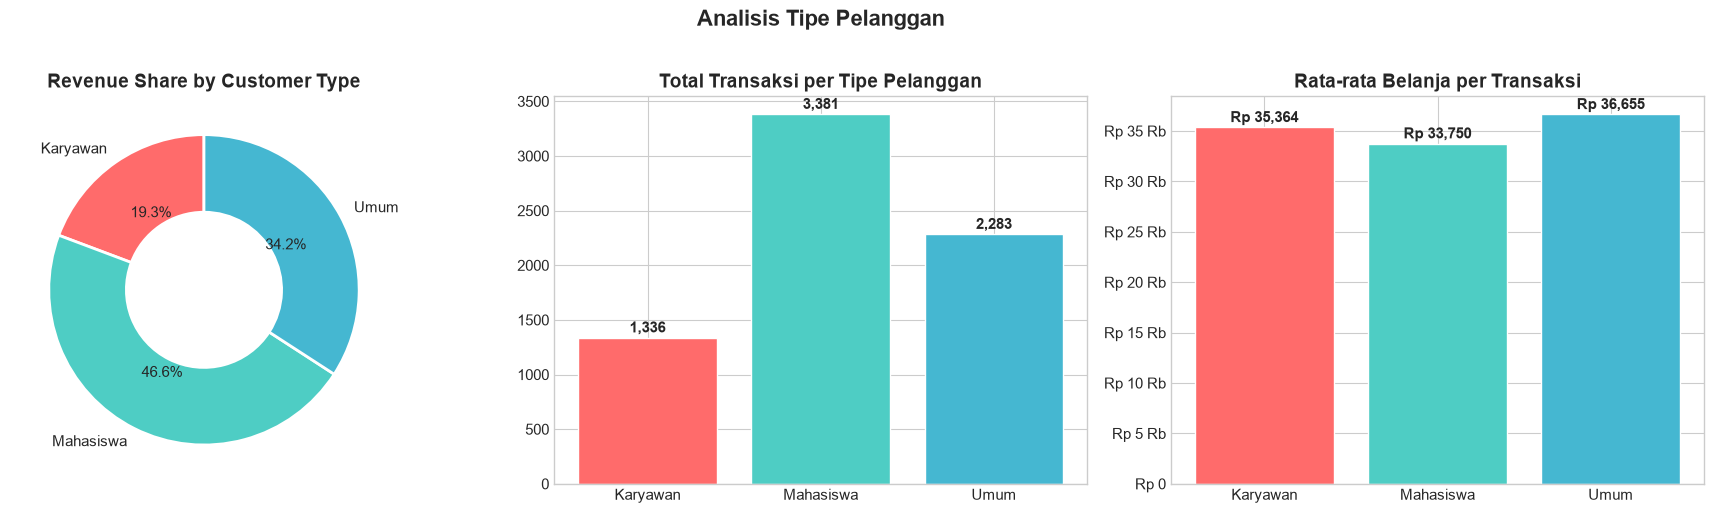

In [21]:
# Visualisasi: Customer Type Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ctype_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

# 1. Revenue Share
axes[0].pie(cust_type['Net_Sales'], labels=cust_type['Customer_Type'],
            autopct='%1.1f%%', colors=ctype_colors, startangle=90,
            wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
            textprops={'fontsize': 11})
axes[0].set_title('Revenue Share by Customer Type')

# 2. Jumlah Transaksi
bars = axes[1].bar(cust_type['Customer_Type'], cust_type['Total_Transaksi'], color=ctype_colors, edgecolor='white')
axes[1].set_title('Total Transaksi per Tipe Pelanggan')
for bar, val in zip(bars, cust_type['Total_Transaksi']):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 20,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold')

# 3. Avg Spend per Transaksi
bars = axes[2].bar(cust_type['Customer_Type'], cust_type['Avg_Spend'], color=ctype_colors, edgecolor='white')
axes[2].set_title('Rata-rata Belanja per Transaksi')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for bar, val in zip(bars, cust_type['Avg_Spend']):
    axes[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 200,
                 f'Rp {val:,.0f}', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Analisis Tipe Pelanggan', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [22]:
# ===== TOP 10 PELANGGAN (by Revenue) =====
top_customers = df.groupby(['Customer_ID', 'Customer_Type']).agg(
    Transaksi=('Transaction_ID', 'count'),
    Total_Qty=('Qty', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index().sort_values('Net_Sales', ascending=False)

print('TOP 10 PELANGGAN BERDASARKAN NET SALES')
print('='*80)
top_customers.head(10)

TOP 10 PELANGGAN BERDASARKAN NET SALES


,Customer_ID,Customer_Type,Transaksi,Total_Qty,Net_Sales,Gross_Profit
988,STU0069,Mahasiswa,18,26,745000,383000
26,EMP0027,Karyawan,18,24,685600,364100
1015,STU0096,Mahasiswa,20,26,684600,371100
1012,STU0093,Mahasiswa,16,21,640000,341500
41,EMP0042,Karyawan,15,20,638000,342500
1079,STU0160,Mahasiswa,19,22,622600,334600
54,EMP0055,Karyawan,15,18,578400,302900
1025,STU0106,Mahasiswa,16,19,577200,298200
986,STU0067,Mahasiswa,17,22,571200,275700
1056,STU0137,Mahasiswa,14,20,569400,293400


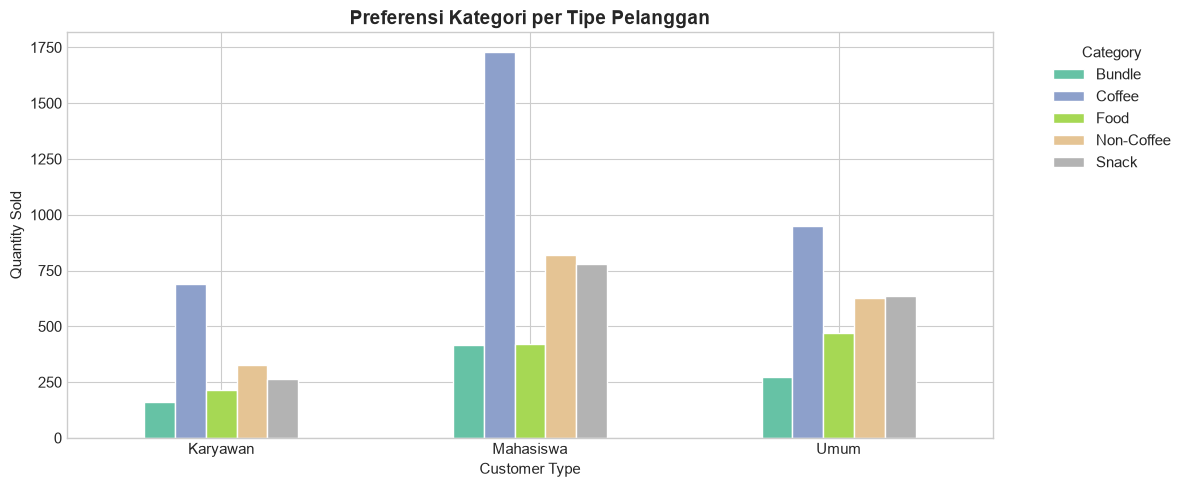

In [23]:
# ===== PREFERENSI PRODUK PER TIPE PELANGGAN =====
pref = df.groupby(['Customer_Type', 'Category']).agg(
    Qty=('Qty', 'sum')
).reset_index()

pref_pivot = pref.pivot_table(index='Customer_Type', columns='Category', values='Qty', fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
pref_pivot.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='white')
ax.set_title('Preferensi Kategori per Tipe Pelanggan', fontweight='bold', fontsize=14)
ax.set_ylabel('Quantity Sold')
ax.set_xlabel('Customer Type')
ax.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 7. Analisis Tren Waktu (Time Series)

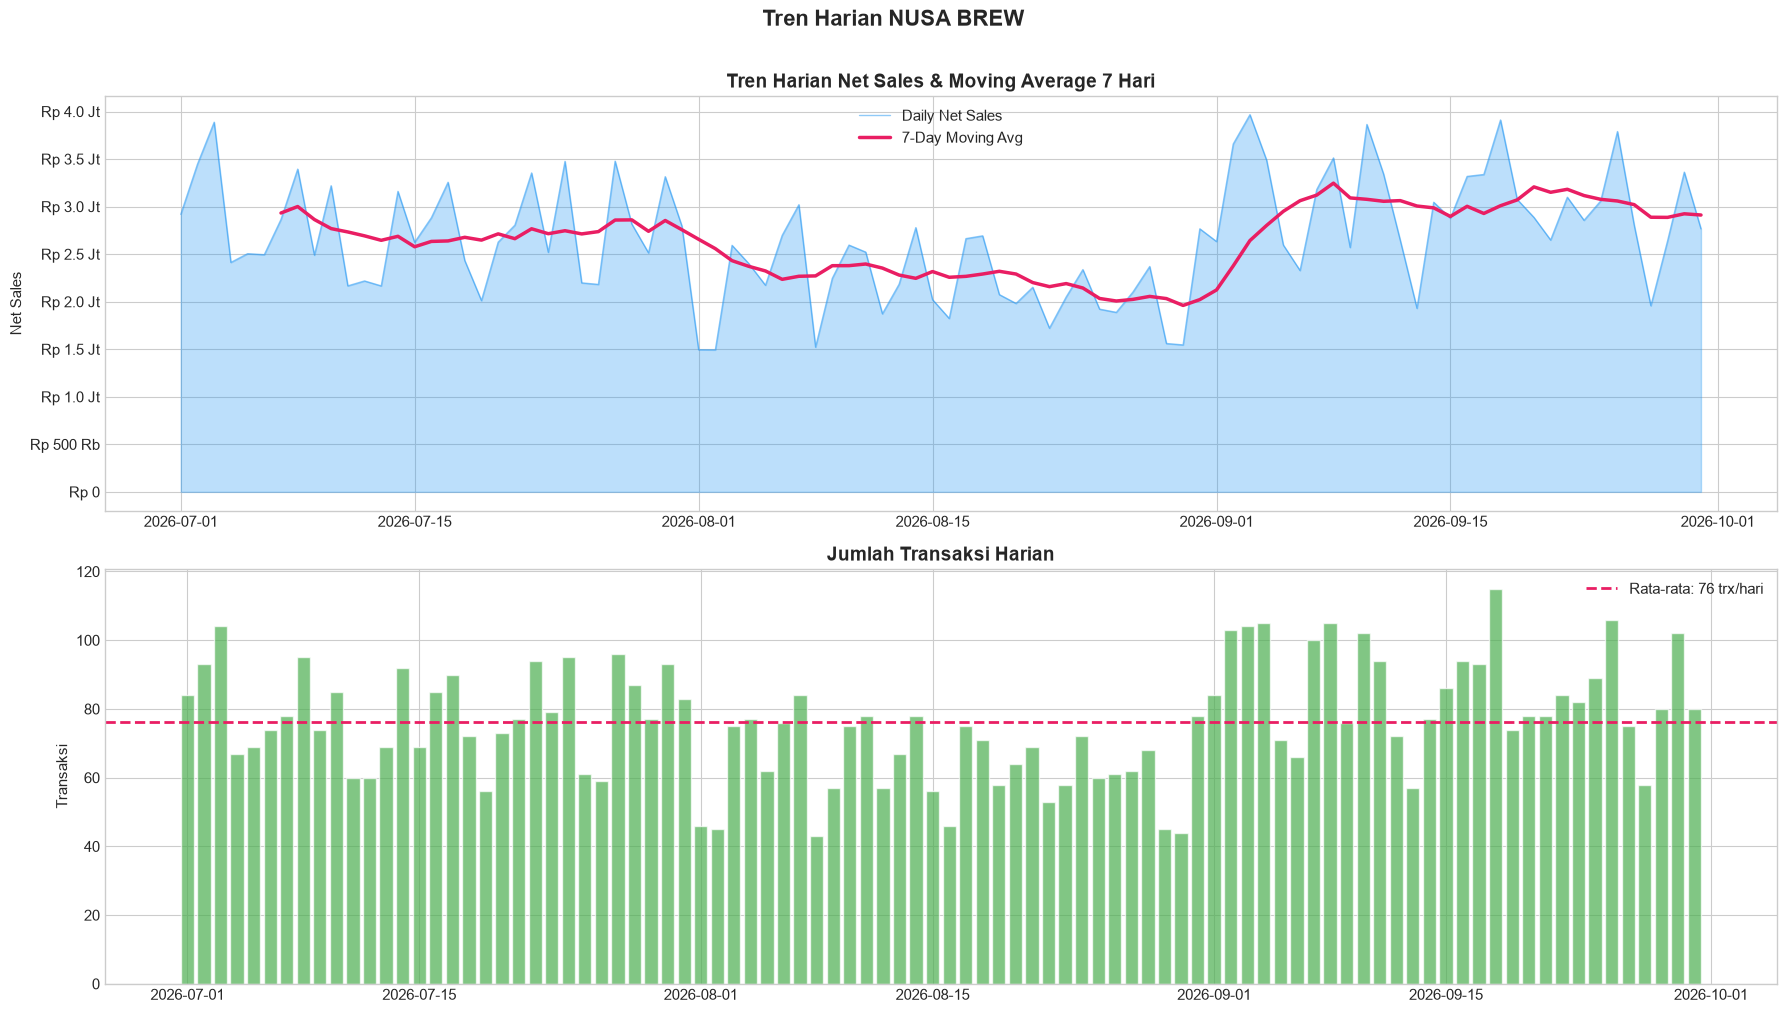


Statistik Harian:
  Avg Net Sales/hari  : Rp 2,663,464
  Max Net Sales       : Rp 3,966,600 (03 September 2026)
  Min Net Sales       : Rp 1,493,200 (02 August 2026)
  Avg Transaksi/hari  : 76


In [24]:
# ===== TREN HARIAN NET SALES =====
daily = df.groupby('Date').agg(
    Transaksi=('Transaction_ID', 'nunique'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum'),
    Qty=('Qty', 'sum')
).reset_index()

daily['Avg_Ticket'] = daily['Net_Sales'] / daily['Transaksi']
daily['MA7'] = daily['Net_Sales'].rolling(window=7).mean()  # Moving Average 7 hari

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# Chart 1: Daily Net Sales + Moving Average
axes[0].fill_between(daily['Date'], daily['Net_Sales'], alpha=0.3, color='#2196F3')
axes[0].plot(daily['Date'], daily['Net_Sales'], color='#2196F3', alpha=0.5, linewidth=1, label='Daily Net Sales')
axes[0].plot(daily['Date'], daily['MA7'], color='#E91E63', linewidth=2.5, label='7-Day Moving Avg')
axes[0].set_title('Tren Harian Net Sales & Moving Average 7 Hari', fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
axes[0].legend(fontsize=11)
axes[0].set_ylabel('Net Sales')

# Chart 2: Daily Transactions
axes[1].bar(daily['Date'], daily['Transaksi'], color='#4CAF50', alpha=0.7, edgecolor='white')
axes[1].axhline(y=daily['Transaksi'].mean(), color='#E91E63', linestyle='--', linewidth=2,
                label=f'Rata-rata: {daily["Transaksi"].mean():.0f} trx/hari')
axes[1].set_title('Jumlah Transaksi Harian', fontweight='bold')
axes[1].set_ylabel('Transaksi')
axes[1].legend(fontsize=11)

plt.suptitle('Tren Harian NUSA BREW', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Statistik harian
print(f'\nStatistik Harian:')
print(f'  Avg Net Sales/hari  : Rp {daily["Net_Sales"].mean():,.0f}')
print(f'  Max Net Sales       : Rp {daily["Net_Sales"].max():,.0f} ({daily.loc[daily["Net_Sales"].idxmax(), "Date"].strftime("%d %B %Y")})')
print(f'  Min Net Sales       : Rp {daily["Net_Sales"].min():,.0f} ({daily.loc[daily["Net_Sales"].idxmin(), "Date"].strftime("%d %B %Y")})')
print(f'  Avg Transaksi/hari  : {daily["Transaksi"].mean():.0f}')

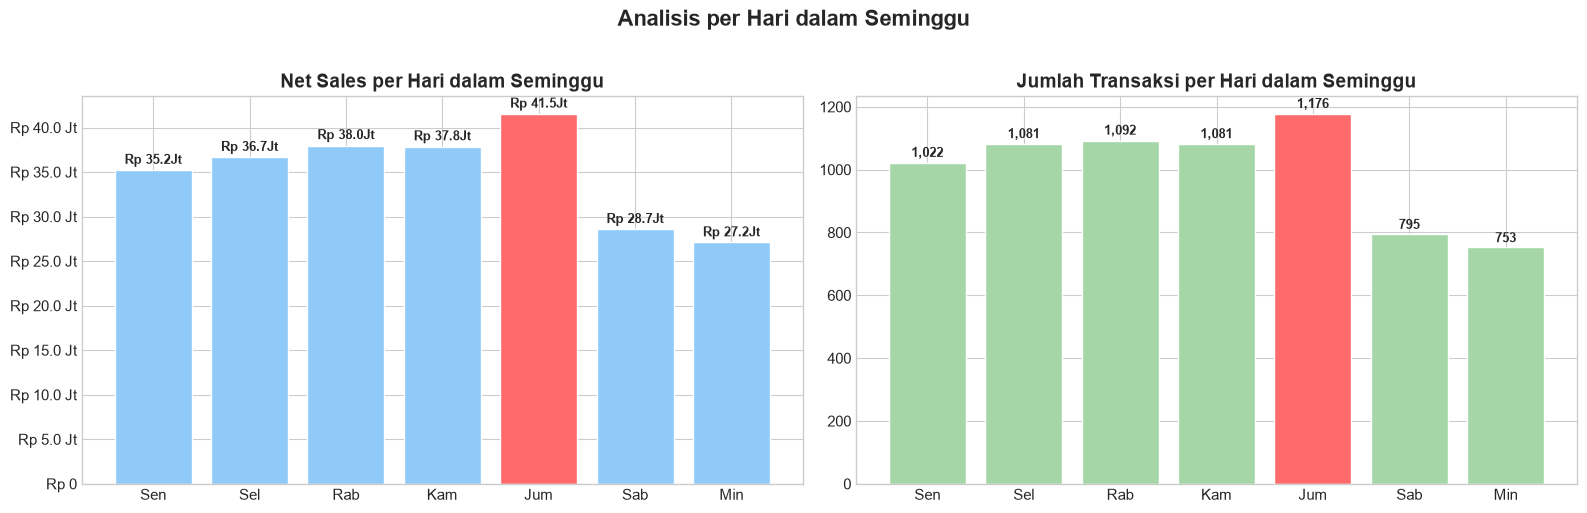

In [25]:
# ===== ANALISIS PER HARI (Day of Week) =====
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_labels = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']

day_sales = df.groupby('Day_of_Week').agg(
    Transaksi=('Transaction_ID', 'count'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reindex(day_order).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Net Sales per Hari
colors_day = ['#FF6B6B' if v == day_sales['Net_Sales'].max() else '#90CAF9' for v in day_sales['Net_Sales']]
axes[0].bar(day_labels, day_sales['Net_Sales'], color=colors_day, edgecolor='white')
axes[0].set_title('Net Sales per Hari dalam Seminggu', fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for i, val in enumerate(day_sales['Net_Sales']):
    axes[0].text(i, val + (val*0.01), f'Rp {val/1_000_000:.1f}Jt', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Transaksi per Hari
colors_trx = ['#FF6B6B' if v == day_sales['Transaksi'].max() else '#A5D6A7' for v in day_sales['Transaksi']]
axes[1].bar(day_labels, day_sales['Transaksi'], color=colors_trx, edgecolor='white')
axes[1].set_title('Jumlah Transaksi per Hari dalam Seminggu', fontweight='bold')
for i, val in enumerate(day_sales['Transaksi']):
    axes[1].text(i, val + (val*0.01), f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Analisis per Hari dalam Seminggu', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

ANALISIS PER SESI WAKTU
  Session  Transaksi   Qty  Net_Sales  Gross_Profit  Avg_Ticket  \
0    Pagi        941  1189   33499550      17725550     35600.0   
1   Siang       2143  2724   75961100      39377600     35446.0   
2    Sore       2507  3067   84872700      43030200     33854.0   
3   Malam       1409  1794   50705350      26172350     35987.0   

   Revenue_Share_%  
0             13.7  
1             31.0  
2             34.6  
3             20.7  


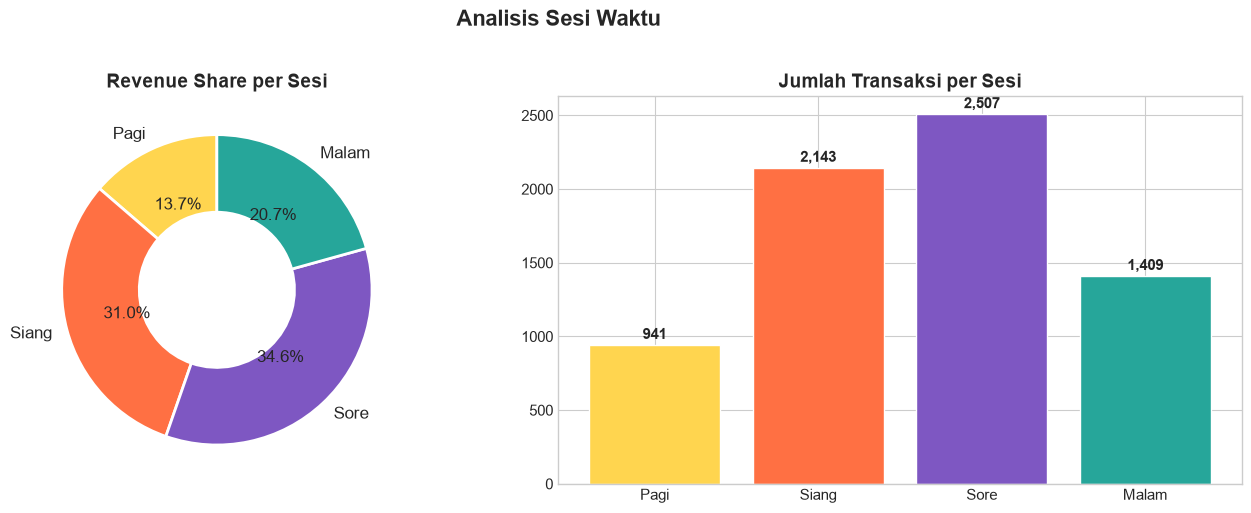

In [26]:
# ===== ANALISIS PER SESI (Pagi / Siang / Sore / Malam) =====
session_order = ['Pagi', 'Siang', 'Sore', 'Malam']
session_sales = df.groupby('Session').agg(
    Transaksi=('Transaction_ID', 'count'),
    Qty=('Qty', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reindex(session_order).dropna().reset_index()

session_sales['Avg_Ticket'] = (session_sales['Net_Sales'] / session_sales['Transaksi']).round(0)
session_sales['Revenue_Share_%'] = (session_sales['Net_Sales'] / session_sales['Net_Sales'].sum() * 100).round(1)

print('ANALISIS PER SESI WAKTU')
print('='*80)
print(session_sales)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

session_colors = ['#FFD54F', '#FF7043', '#7E57C2', '#26A69A']

axes[0].pie(session_sales['Net_Sales'], labels=session_sales['Session'],
            autopct='%1.1f%%', colors=session_colors[:len(session_sales)], startangle=90,
            wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
            textprops={'fontsize': 12})
axes[0].set_title('Revenue Share per Sesi', fontweight='bold')

axes[1].bar(session_sales['Session'], session_sales['Transaksi'],
            color=session_colors[:len(session_sales)], edgecolor='white')
axes[1].set_title('Jumlah Transaksi per Sesi', fontweight='bold')
for i, (val, session) in enumerate(zip(session_sales['Transaksi'], session_sales['Session'])):
    axes[1].text(i, val + 20, f'{val:,.0f}', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Analisis Sesi Waktu', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

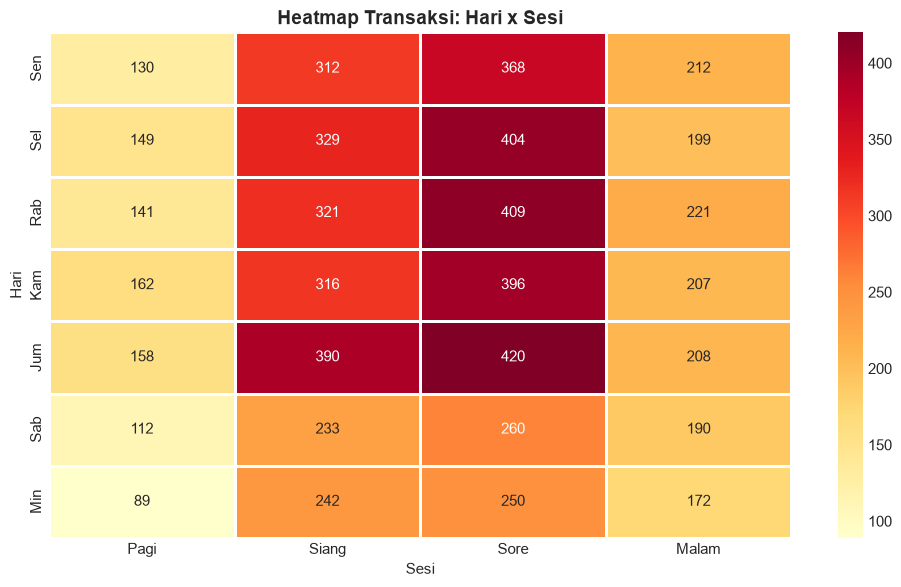

In [27]:
# ===== HEATMAP: Hari x Sesi =====
heatmap_data = df.groupby(['Day_of_Week', 'Session']).agg(
    Transaksi=('Transaction_ID', 'count')
).reset_index()

heatmap_pivot = heatmap_data.pivot_table(index='Day_of_Week', columns='Session', values='Transaksi', fill_value=0)

# Reindex hari dalam urutan yang benar
heatmap_pivot = heatmap_pivot.reindex(day_order)
# Reindex sesi dalam urutan yang benar
session_cols_available = [s for s in session_order if s in heatmap_pivot.columns]
heatmap_pivot = heatmap_pivot[session_cols_available]

# Ganti label hari ke Indonesia
day_map_id = dict(zip(day_order, day_labels))
heatmap_pivot.index = [day_map_id.get(d, d) for d in heatmap_pivot.index]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heatmap_pivot, annot=True, fmt='g', cmap='YlOrRd', linewidths=1, linecolor='white', ax=ax)
ax.set_title('Heatmap Transaksi: Hari x Sesi', fontweight='bold', fontsize=14)
ax.set_ylabel('Hari')
ax.set_xlabel('Sesi')
plt.tight_layout()
plt.show()

---
## 8. Analisis Promosi & Diskon

In [28]:
# ===== DAMPAK PROMO (semua jenis: DISKON20, MORNING10, BUNDLE15, Tanpa Promo) =====
promo_analysis = df.groupby('Promo').agg(
    Transaksi=('Transaction_ID', 'count'),
    Qty=('Qty', 'sum'),
    Gross_Sales=('Gross_Sales', 'sum'),
    Discount_Amt=('Discount_Amt', 'sum'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index()

promo_analysis['Avg_Ticket'] = (promo_analysis['Net_Sales'] / promo_analysis['Transaksi']).round(0)
promo_analysis['Margin_%'] = (promo_analysis['Gross_Profit'] / promo_analysis['Net_Sales'] * 100).round(1)
promo_analysis['Trx_Share_%'] = (promo_analysis['Transaksi'] / promo_analysis['Transaksi'].sum() * 100).round(1)

print('ANALISIS DAMPAK PROMOSI')
print('='*80)
promo_analysis

ANALISIS DAMPAK PROMOSI


,Promo,Transaksi,Qty,Gross_Sales,Discount_Amt,Net_Sales,Gross_Profit,Avg_Ticket,Margin_%,Trx_Share_%
0,BUNDLE15,11,12,520000,78000,442000,200000,40182.0,45.2,0.2
1,DISKON20,783,969,27675000,5535000,22140000,8991500,28276.0,40.6,11.2
2,MORNING10,21,25,733000,73300,659700,308200,31414.0,46.7,0.3
3,Tanpa Promo,6185,7768,221797000,0,221797000,116806000,35860.0,52.7,88.4


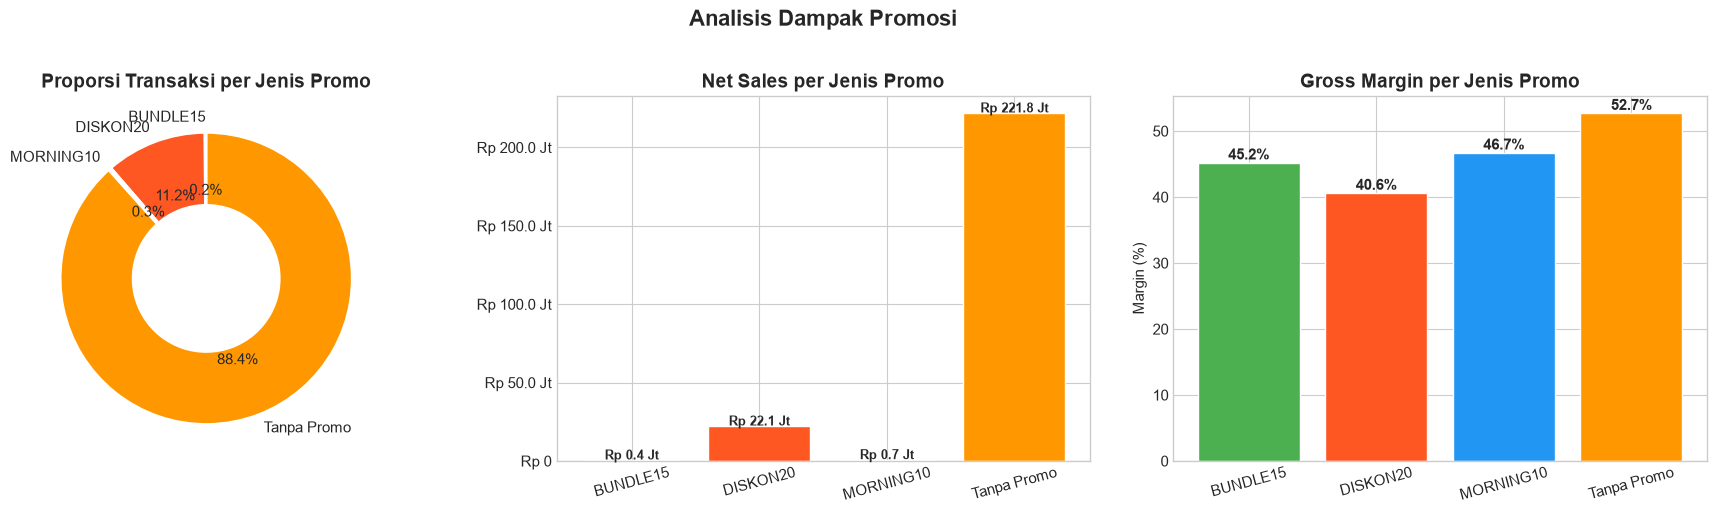


Total Diskon yang Diberikan: Rp 5,686,300


In [29]:
# Visualisasi Promo Impact
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

promo_colors = ['#4CAF50', '#FF5722', '#2196F3', '#FF9800']

# 1. Transaksi
axes[0].pie(promo_analysis['Transaksi'], labels=promo_analysis['Promo'],
            autopct='%1.1f%%', colors=promo_colors[:len(promo_analysis)], startangle=90,
            wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2))
axes[0].set_title('Proporsi Transaksi per Jenis Promo')

# 2. Net Sales comparison
bars = axes[1].bar(promo_analysis['Promo'], promo_analysis['Net_Sales'],
                   color=promo_colors[:len(promo_analysis)], edgecolor='white')
axes[1].set_title('Net Sales per Jenis Promo')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
axes[1].tick_params(axis='x', rotation=15)
for bar, val in zip(bars, promo_analysis['Net_Sales']):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 500000,
                 f'Rp {val/1_000_000:.1f} Jt', ha='center', fontweight='bold', fontsize=9)

# 3. Margin comparison
bars = axes[2].bar(promo_analysis['Promo'], promo_analysis['Margin_%'],
                   color=promo_colors[:len(promo_analysis)], edgecolor='white')
axes[2].set_title('Gross Margin per Jenis Promo')
axes[2].set_ylabel('Margin (%)')
axes[2].tick_params(axis='x', rotation=15)
for bar, val in zip(bars, promo_analysis['Margin_%']):
    axes[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                 f'{val}%', ha='center', fontweight='bold')

plt.suptitle('Analisis Dampak Promosi', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'\nTotal Diskon yang Diberikan: Rp {promo_analysis["Discount_Amt"].sum():,.0f}')

---
## 9. Analisis Tipe Order & Metode Pembayaran

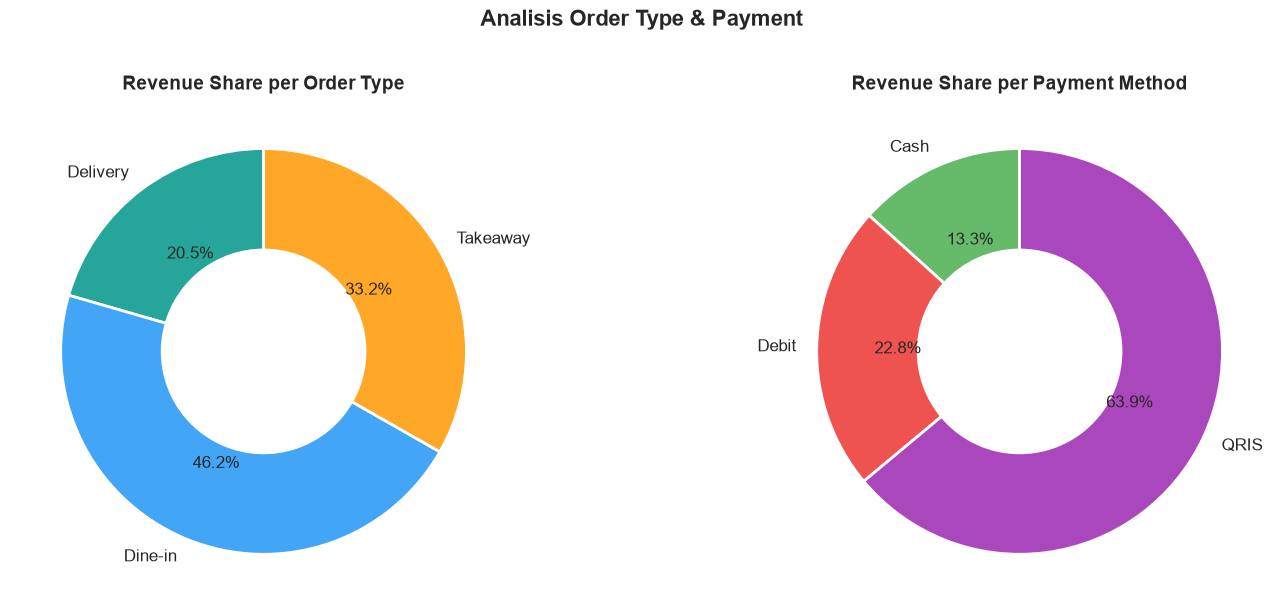


ORDER TYPE
Order_Type  Transaksi  Net_Sales  Gross_Profit  Avg_Ticket  Share_%
  Delivery       1421   50314400      26034400     35408.0     20.5
   Dine-in       3244  113275500      58300500     34918.0     46.2
  Takeaway       2335   81448800      41970800     34882.0     33.2

PAYMENT METHOD
Payment  Transaksi  Net_Sales  Share_%
   Cash        928   32607200     13.3
  Debit       1598   55750250     22.8
   QRIS       4474  156681250     63.9


In [30]:
# ===== ANALISIS ORDER TYPE =====
order_analysis = df.groupby('Order_Type').agg(
    Transaksi=('Transaction_ID', 'count'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index()

order_analysis['Avg_Ticket'] = (order_analysis['Net_Sales'] / order_analysis['Transaksi']).round(0)
order_analysis['Share_%'] = (order_analysis['Net_Sales'] / order_analysis['Net_Sales'].sum() * 100).round(1)

# ===== ANALISIS PAYMENT METHOD =====
payment_analysis = df.groupby('Payment').agg(
    Transaksi=('Transaction_ID', 'count'),
    Net_Sales=('Net_Sales', 'sum')
).reset_index()

payment_analysis['Share_%'] = (payment_analysis['Net_Sales'] / payment_analysis['Net_Sales'].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Order Type
order_colors = ['#26A69A', '#42A5F5', '#FFA726']
wedges1, texts1, autotexts1 = axes[0].pie(
    order_analysis['Net_Sales'], labels=order_analysis['Order_Type'],
    autopct='%1.1f%%', colors=order_colors, startangle=90,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12})
axes[0].set_title('Revenue Share per Order Type', fontweight='bold')

# Payment Method
pay_colors = ['#66BB6A', '#EF5350', '#AB47BC']
wedges2, texts2, autotexts2 = axes[1].pie(
    payment_analysis['Net_Sales'], labels=payment_analysis['Payment'],
    autopct='%1.1f%%', colors=pay_colors, startangle=90,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12})
axes[1].set_title('Revenue Share per Payment Method', fontweight='bold')

plt.suptitle('Analisis Order Type & Payment', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\nORDER TYPE')
print(order_analysis.to_string(index=False))
print('\nPAYMENT METHOD')
print(payment_analysis.to_string(index=False))

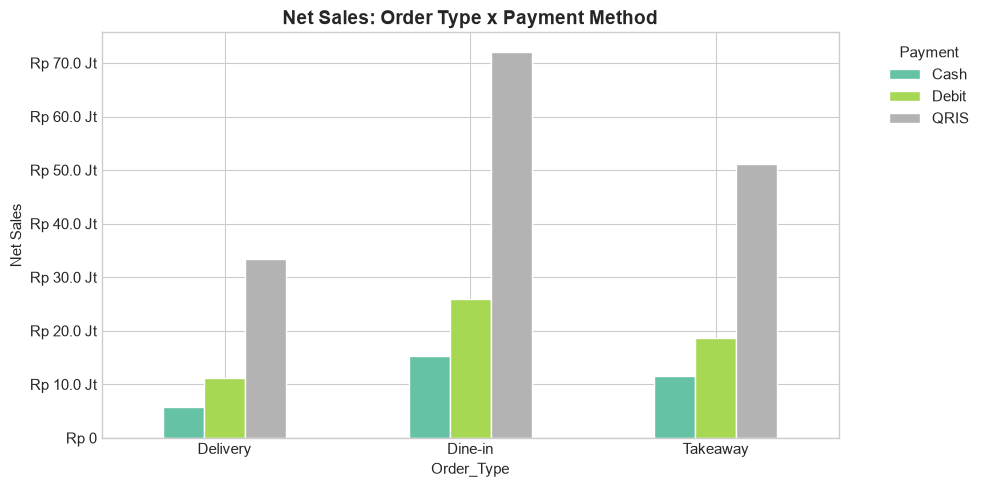

In [31]:
# ===== CROSS ANALYSIS: Order Type x Payment =====
cross = pd.crosstab(df['Order_Type'], df['Payment'], values=df['Net_Sales'], aggfunc='sum')

fig, ax = plt.subplots(figsize=(10, 5))
cross.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='white')
ax.set_title('Net Sales: Order Type x Payment Method', fontweight='bold', fontsize=14)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
ax.legend(title='Payment', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_ylabel('Net Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 10. Analisis Profitabilitas

In [32]:
# ===== PROFITABILITAS BULANAN DENGAN OPEX =====
# Data OPEX
print('DATA BIAYA OPERASIONAL (OPEX)')
print('='*80)
print(df_opex)

# Mapping bulan ke Month period
month_map = {
    'Juli': '2026-07', 'Agustus': '2026-08', 'September': '2026-09'
}

# Buat tabel profitabilitas lengkap
profit_monthly = monthly_sales[['Month', 'Net_Sales', 'COGS', 'Gross_Profit']].copy()
profit_monthly['Month_str'] = profit_monthly['Month'].astype(str)

# Map OPEX dari dataframe
opex_dict = {}
for _, row in df_opex.iterrows():
    month_name = str(row['Month']).strip()
    if month_name in month_map:
        opex_val = row['OPEX Total']
        if isinstance(opex_val, str):
            opex_val = float(opex_val.replace('Rp', '').replace('.', '').replace(',', '.').strip())
        opex_dict[month_map[month_name]] = float(opex_val)

print(f'\nOPEX mapping: {opex_dict}')

profit_monthly['OPEX'] = profit_monthly['Month_str'].map(opex_dict).fillna(29_000_000)
profit_monthly['Net_Profit'] = profit_monthly['Gross_Profit'] - profit_monthly['OPEX']
profit_monthly['Net_Margin_%'] = (profit_monthly['Net_Profit'] / profit_monthly['Net_Sales'] * 100).round(1)

print('\n\nLAPORAN PROFITABILITAS BULANAN')
print('='*80)
profit_monthly[['Month', 'Net_Sales', 'COGS', 'Gross_Profit', 'OPEX', 'Net_Profit', 'Net_Margin_%']]

DATA BIAYA OPERASIONAL (OPEX)
       Month     Staff      Rent  Utilities  Marketing    Other  OPEX Total  \
0       Juli  10000000  10000000    4500000    2500000  2000000    29000000   
1    Agustus  10000001  10000000    4500000    2500000  2000000    29000001   
2  September  10000002  10000000    4500000    2500000  2000000    29000002   

           Source  
0  Scenario input  
1  Scenario input  
2  Scenario input  

OPEX mapping: {'2026-07': 29000000.0, '2026-08': 29000001.0, '2026-09': 29000002.0}


LAPORAN PROFITABILITAS BULANAN


,Month,Net_Sales,COGS,Gross_Profit,OPEX,Net_Profit,Net_Margin_%
0,2026-07,86628700,41748500,44880200,29000000.0,15880200.0,18.3
1,2026-08,67262200,33322000,33940200,29000001.0,4940199.0,7.3
2,2026-09,91147800,43662500,47485300,29000002.0,18485298.0,20.3


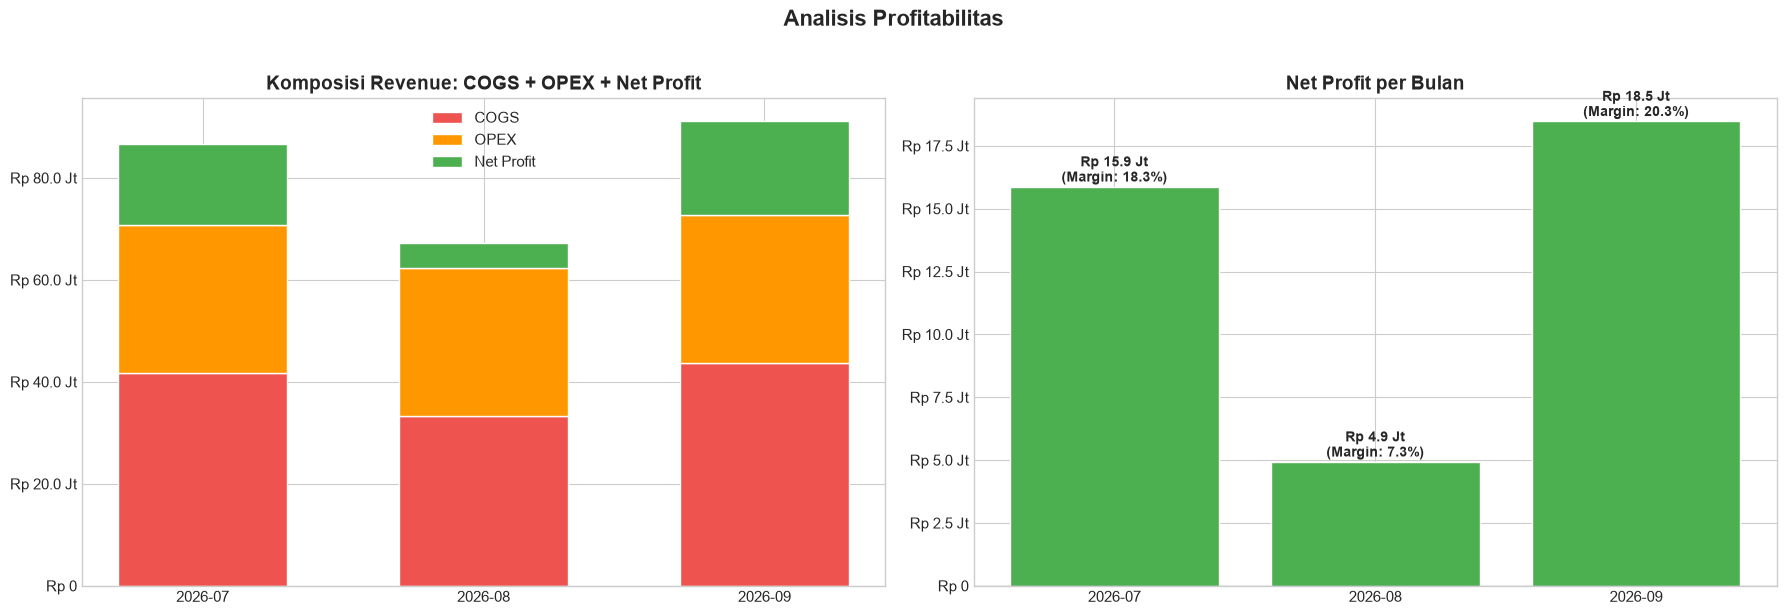


RINGKASAN PROFITABILITAS (3 Bulan):
  Total Net Sales   : Rp  245,038,700
  Total COGS        : Rp  118,733,000
  Total Gross Profit: Rp  126,305,700
  Total OPEX        : Rp   87,000,003
  Total Net Profit  : Rp   39,305,697
  Net Margin        : 16.0%


In [33]:
# Visualisasi: P&L
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

months_str = profit_monthly['Month'].astype(str).tolist()

# 1. Stacked: Revenue breakdown
x = np.arange(len(months_str))
width = 0.6
axes[0].bar(x, profit_monthly['COGS'], width, label='COGS', color='#EF5350', edgecolor='white')
axes[0].bar(x, profit_monthly['OPEX'], width, bottom=profit_monthly['COGS'], label='OPEX', color='#FF9800', edgecolor='white')
axes[0].bar(x, profit_monthly['Net_Profit'], width,
            bottom=profit_monthly['COGS'] + profit_monthly['OPEX'],
            label='Net Profit', color='#4CAF50', edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(months_str)
axes[0].set_title('Komposisi Revenue: COGS + OPEX + Net Profit', fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
axes[0].legend()

# 2. Net Profit trend
colors_np = ['#4CAF50' if v >= 0 else '#EF5350' for v in profit_monthly['Net_Profit']]
bars = axes[1].bar(months_str, profit_monthly['Net_Profit'], color=colors_np, edgecolor='white')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].set_title('Net Profit per Bulan', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
for bar, val, margin in zip(bars, profit_monthly['Net_Profit'], profit_monthly['Net_Margin_%']):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 200000,
                 f'Rp {val/1_000_000:.1f} Jt\n(Margin: {margin}%)', ha='center', fontweight='bold', fontsize=10)

plt.suptitle('Analisis Profitabilitas', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Ringkasan total
total_net_profit = profit_monthly['Net_Profit'].sum()
total_opex = profit_monthly['OPEX'].sum()
print(f'\nRINGKASAN PROFITABILITAS (3 Bulan):')
print(f'  Total Net Sales   : Rp {total_net_sales:>12,.0f}')
print(f'  Total COGS        : Rp {total_cogs:>12,.0f}')
print(f'  Total Gross Profit: Rp {total_gross_profit:>12,.0f}')
print(f'  Total OPEX        : Rp {total_opex:>12,.0f}')
print(f'  Total Net Profit  : Rp {total_net_profit:>12,.0f}')
print(f'  Net Margin        : {(total_net_profit/total_net_sales*100):.1f}%')

In [34]:
# ===== KATALOG PRODUK: Unit Economics =====
print('KATALOG PRODUK & UNIT ECONOMICS')
print('='*80)
df_catalog

KATALOG PRODUK & UNIT ECONOMICS


,Product,Category,Unit Price,Unit COGS,Margin at List Price
0,Breakfast Combo,Bundle,45000,21000,0.533333
1,Study Combo,Bundle,43000,20000,0.534884
2,Americano,Coffee,25000,9000,0.640000
3,Café Latte,Coffee,30000,12500,0.583333
4,Cappuccino,Coffee,30000,12500,0.583333
5,Espresso,Coffee,22000,8000,0.636364
6,Iced Aren Coffee,Coffee,24000,15000,0.375000
7,Beef Rice Bowl,Food,39000,22000,0.435897
8,Chicken Rice Bowl,Food,35000,19000,0.457143
9,Chocolate,Non-Coffee,29000,12500,0.568966


---
## 11. Analisis Korelasi & Insight Lanjutan

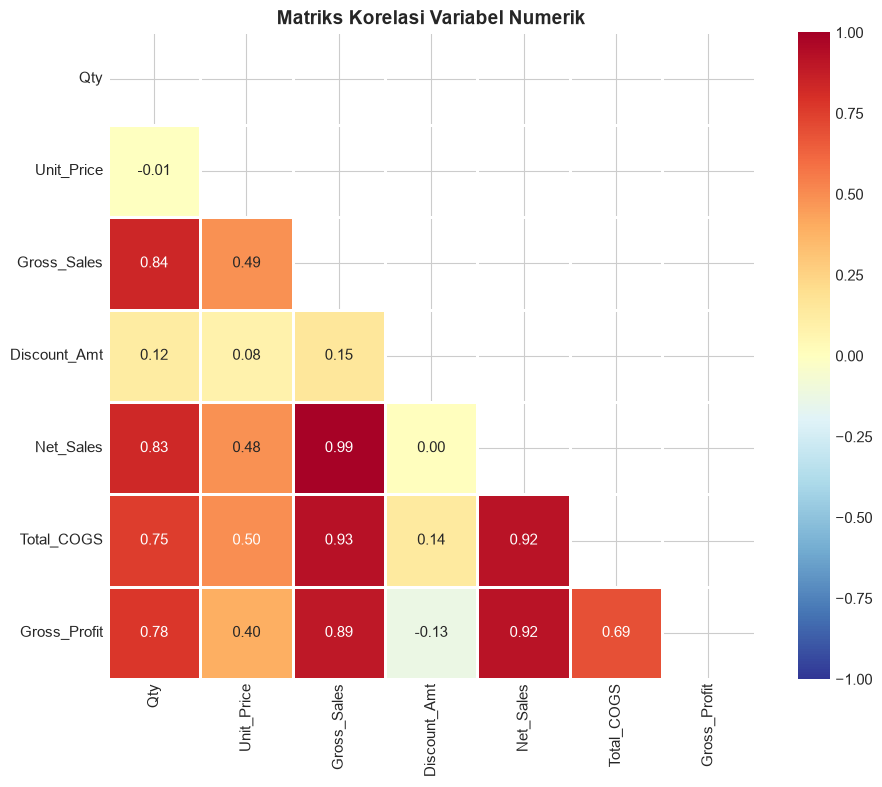

In [35]:
# ===== KORELASI ANTAR VARIABEL NUMERIK =====
corr_cols = ['Qty', 'Unit_Price', 'Gross_Sales', 'Discount_Amt', 'Net_Sales', 'Total_COGS', 'Gross_Profit']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu_r',
            center=0, square=True, linewidths=1, linecolor='white',
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Matriks Korelasi Variabel Numerik', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

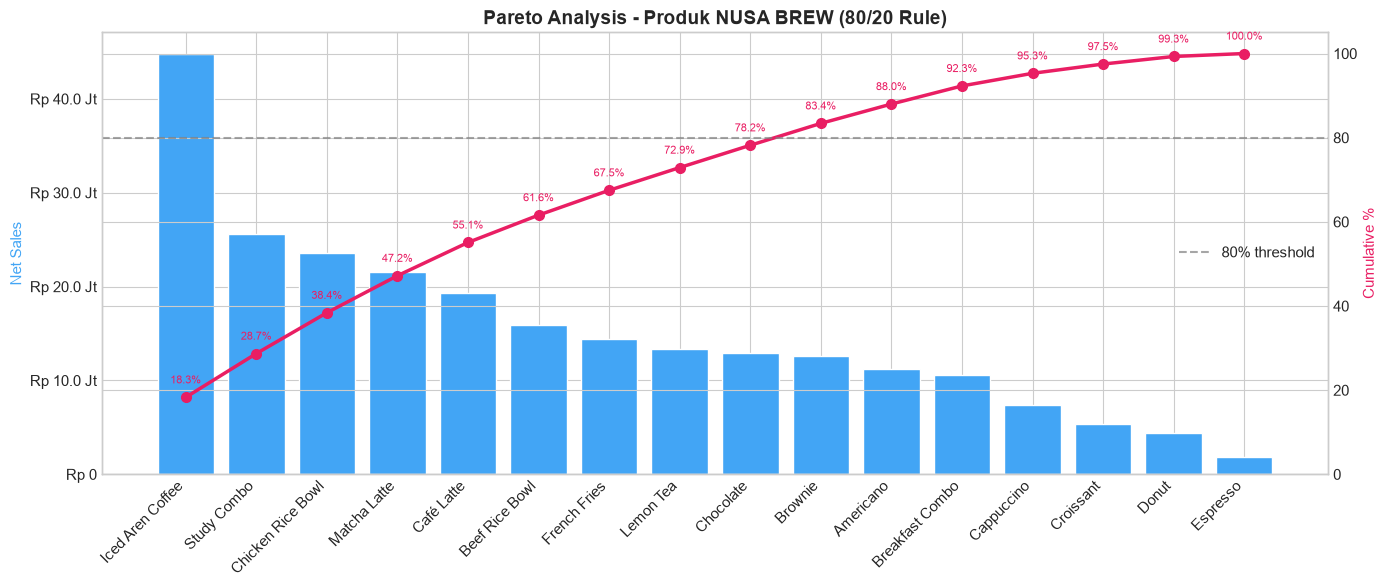


Produk yang menghasilkan ~80% revenue: 9 dari 16 produk
          Product   Category  Net_Sales  Cumulative_%
 Iced Aren Coffee     Coffee   44832000          18.3
      Study Combo     Bundle   25580700          28.7
Chicken Rice Bowl       Food   23593500          38.4
     Matcha Latte Non-Coffee   21606400          47.2
       Café Latte     Coffee   19344000          55.1
   Beef Rice Bowl       Food   15939300          61.6
     French Fries      Snack   14421600          67.5
        Lemon Tea Non-Coffee   13365000          72.9
        Chocolate Non-Coffee   12951400          78.2


In [36]:
# ===== PARETO ANALYSIS (80/20 Rule) =====
pareto = product_sales.sort_values('Net_Sales', ascending=False).copy()
pareto['Cumulative_%'] = (pareto['Net_Sales'].cumsum() / pareto['Net_Sales'].sum() * 100).round(1)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar chart
bars = ax1.bar(range(len(pareto)), pareto['Net_Sales'], color='#42A5F5', edgecolor='white')
ax1.set_xticks(range(len(pareto)))
ax1.set_xticklabels(pareto['Product'], rotation=45, ha='right')
ax1.set_ylabel('Net Sales', color='#42A5F5')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))

# Cumulative line
ax2 = ax1.twinx()
ax2.plot(range(len(pareto)), pareto['Cumulative_%'].values, color='#E91E63', marker='o', linewidth=2.5, markersize=7)
ax2.axhline(y=80, color='gray', linestyle='--', alpha=0.7, label='80% threshold')
ax2.set_ylabel('Cumulative %', color='#E91E63')
ax2.set_ylim(0, 105)

# Anotasi
for i, pct in enumerate(pareto['Cumulative_%']):
    ax2.annotate(f'{pct}%', (i, pct), textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=8, color='#E91E63')

ax1.set_title('Pareto Analysis - Produk NUSA BREW (80/20 Rule)', fontweight='bold', fontsize=14)
ax2.legend(loc='center right')
plt.tight_layout()
plt.show()

# Produk yang menghasilkan 80% revenue
top80 = pareto[pareto['Cumulative_%'] <= 80]
print(f'\nProduk yang menghasilkan ~80% revenue: {len(top80)} dari {len(pareto)} produk')
print(top80[['Product', 'Category', 'Net_Sales', 'Cumulative_%']].to_string(index=False))

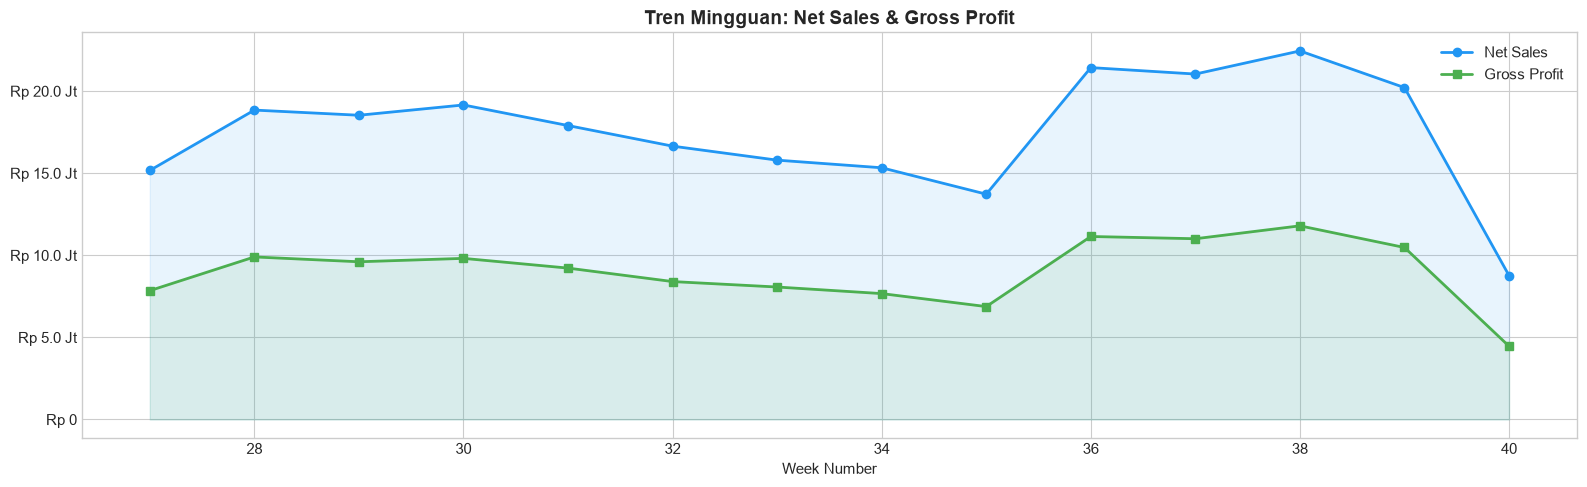

In [37]:
# ===== ANALISIS TREN MINGGUAN =====
weekly = df.groupby('Week').agg(
    Transaksi=('Transaction_ID', 'nunique'),
    Net_Sales=('Net_Sales', 'sum'),
    Gross_Profit=('Gross_Profit', 'sum')
).reset_index()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(weekly['Week'], weekly['Net_Sales'], marker='o', linewidth=2, color='#2196F3', markersize=6, label='Net Sales')
ax.plot(weekly['Week'], weekly['Gross_Profit'], marker='s', linewidth=2, color='#4CAF50', markersize=6, label='Gross Profit')
ax.fill_between(weekly['Week'], weekly['Net_Sales'], alpha=0.1, color='#2196F3')
ax.fill_between(weekly['Week'], weekly['Gross_Profit'], alpha=0.1, color='#4CAF50')
ax.set_title('Tren Mingguan: Net Sales & Gross Profit', fontweight='bold', fontsize=14)
ax.set_xlabel('Week Number')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_rupiah))
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## 12. Kesimpulan & Rekomendasi

In [38]:
# ===== EXECUTIVE SUMMARY =====
print('='*70)
print('     EXECUTIVE SUMMARY - NUSA BREW COFFEE SHOP')
print('     Periode: 1 Juli - 30 September 2026 (92 Hari)')
print('='*70)

print(f'''
PERFORMA KESELURUHAN:
  - Total Transaksi       : {total_transactions:,} transaksi
  - Total Item Terjual    : {total_items_sold:,.0f} item
  - Net Sales             : Rp {total_net_sales:,.0f}
  - Gross Profit          : Rp {total_gross_profit:,.0f} (Margin: {gross_margin:.1f}%)
  - Net Profit (est.)     : Rp {total_net_profit:,.0f} (Margin: {(total_net_profit/total_net_sales*100):.1f}%)
  - Avg Ticket Size       : Rp {avg_ticket:,.0f}
  - Avg Transaksi/Hari    : {daily["Transaksi"].mean():.0f} transaksi

TOP INSIGHTS:
  1. Kategori revenue tertinggi  : {cat_sales.iloc[0]["Category"]} (Rp {cat_sales.iloc[0]["Net_Sales"]:,.0f})
  2. Produk best-seller (revenue): {product_sales.sort_values("Net_Sales", ascending=False).iloc[0]["Product"]}
  3. Produk best-seller (qty)    : {product_sales.sort_values("Qty", ascending=False).iloc[0]["Product"]}
  4. Tipe pelanggan terbanyak    : {cust_type.sort_values("Total_Transaksi", ascending=False).iloc[0]["Customer_Type"]}
  5. Metode pembayaran utama     : {payment_analysis.sort_values("Transaksi", ascending=False).iloc[0]["Payment"]}
  6. Order type favorit          : {order_analysis.sort_values("Transaksi", ascending=False).iloc[0]["Order_Type"]}
''')

print('='*70)
print('REKOMENDASI STRATEGIS:')
print('='*70)
print('''
1. OPTIMASI PRODUK:
   - Fokuskan marketing pada produk-produk top performer
   - Evaluasi produk dengan margin rendah (< 50%), pertimbangkan kenaikan harga
     atau optimasi biaya bahan baku

2. STRATEGI PELANGGAN:
   - Buat program loyalty untuk pelanggan dengan repeat order tinggi
   - Targetkan segmen pelanggan dengan spending tertinggi

3. OPTIMASI WAKTU:
   - Sesuaikan staffing berdasarkan pola trafik per sesi dan hari
   - Buat promo khusus untuk sesi/hari dengan trafik rendah

4. STRATEGI PROMO:
   - Evaluasi efektivitas masing-masing promo (DISKON20, MORNING10, BUNDLE15)
   - Bandingkan margin promo vs non-promo untuk optimasi strategi diskon
   - Pertimbangkan promo bundle untuk meningkatkan avg ticket size

5. PROFITABILITAS:
   - Monitor rasio OPEX terhadap revenue agar tetap efisien
   - Fokus pada produk high-margin untuk meningkatkan gross profit
''')

     EXECUTIVE SUMMARY - NUSA BREW COFFEE SHOP
     Periode: 1 Juli - 30 September 2026 (92 Hari)

PERFORMA KESELURUHAN:
  - Total Transaksi       : 7,000 transaksi
  - Total Item Terjual    : 8,774 item
  - Net Sales             : Rp 245,038,700
  - Gross Profit          : Rp 126,305,700 (Margin: 51.5%)
  - Net Profit (est.)     : Rp 39,305,697 (Margin: 16.0%)
  - Avg Ticket Size       : Rp 35,006
  - Avg Transaksi/Hari    : 76 transaksi

TOP INSIGHTS:
  1. Kategori revenue tertinggi  : Coffee (Rp 84,617,500)
  2. Produk best-seller (revenue): Iced Aren Coffee
  3. Produk best-seller (qty)    : Iced Aren Coffee
  4. Tipe pelanggan terbanyak    : Mahasiswa
  5. Metode pembayaran utama     : QRIS
  6. Order type favorit          : Dine-in

REKOMENDASI STRATEGIS:

1. OPTIMASI PRODUK:
   - Fokuskan marketing pada produk-produk top performer
   - Evaluasi produk dengan margin rendah (< 50%), pertimbangkan kenaikan harga
     atau optimasi biaya bahan baku

2. STRATEGI PELANGGAN:
   - Buat 

In [39]:
print('\nAnalisis selesai! Notebook ini dapat digunakan sebagai dasar untuk:')
print('  - Laporan bisnis bulanan / kuartalan')
print('  - Presentasi kepada stakeholder')
print('  - Dasar pengambilan keputusan strategis')
print('  - Dashboard monitoring performa')


Analisis selesai! Notebook ini dapat digunakan sebagai dasar untuk:
  - Laporan bisnis bulanan / kuartalan
  - Presentasi kepada stakeholder
  - Dasar pengambilan keputusan strategis
  - Dashboard monitoring performa
